# Final preprocessing of the dataset (no blur)

For each selected image of `train` and `val`:

1. Crop the black borders of the dermatoscope
2. Central square + resize to 512x512
3. Color constancy (Shades of Gray, p=6, with optional brightness normalization)
4. Hair removal (cross-shaped black-hat + shape filter + inpainting, detected at 256 px)
5. Segmentation: Otsu on the S channel (directly on the image, no blur) + morphological cleaning

The functions live in **`../preprocessing/`** (the same ones used by `Multiclass/01_preprocess_dataset_multiclass.ipynb`);
this notebook only sets the paths and the parameters. Before processing the whole dataset, a few **step-by-step
examples** are shown with the parameters used.

Reads the images from `train/{class}` and `val/{class}` (classes `nevus`, `others`) and saves to `preprocessed2/{split}/{class}/`:

- `<name>_preprocessed.png` (RGB 512x512, no blur, lossless PNG)
- `<name>_mask.png` (0/255, uint8, 512x512, aligned with the previous one)

plus a `preprocessed2/manifest.csv` with one row per image.

The process is **resumable**: if both files of an image already exist, it is not processed again.
The selection uses a fixed seed and is stratified by class and subtype, keeping the real proportions of the dataset.

In [ ]:
%load_ext autoreload
%autoreload 2

import os
import sys
import time
from collections import Counter
from pathlib import Path

# the preprocessing/ package lives in the repo folder, next to Binary/ and Multiclass/
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "preprocessing").is_dir())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
os.environ["PYTHONPATH"] = os.pathsep.join([str(REPO), os.environ.get("PYTHONPATH", "")])   # for the joblib workers

from preprocessing import (PreprocParams, contact_sheet, pick_examples, run_dataset, select_images,
                           show_examples, subtype, summarize_manifest, update_manifest)

# ---------------- Configuration ----------------
ROOT = REPO                       # folder with the data; change it if the data is elsewhere, e.g. Path(r"D:\data\melanoma")
DATA_DIR = ROOT                   # contains train/{nevus,others} and val/{nevus,others}
OUT_DIR = ROOT / "preprocessed2"  # the new images are saved here
CLASSES = ["nevus", "others"]

N_TRAIN = None            # None = all images
N_VAL = None              # None = all images
SEED = 42
OVERWRITE = False         # True = reprocess even if the output files already exist
N_JOBS = 4                # cores to use (-1 = all, -2 = all but one)

# Preprocessing parameters: the SAME in Binary and Multiclass (defaults in preprocessing/params.py)
P = PreprocParams(
    dark_thr=35,                  # 1. borders: gray < dark_thr = black
    min_area_frac=0.08,           # 1. borders: if the useful rectangle is smaller than this fraction, no crop is done
    target_size=512,              # 2. central square + resize
    sog_p=6,                      # 3. Shades of Gray
    normalize_brightness=True,    # 3. True = the estimated light is mapped to gray sog_target; False = only the tint is corrected
    sog_target=195.0,
    hair=dict(kernel_size=5,      # 4. hair (teammate's method): black-hat kernel width > hair thickness
              thresh=15,          #    minimum black-hat value to count as hair
              kernel_shape="cross",
              channel="gray",
              blur_ksize=3,       #    smooths the black-hat map to join broken hairs
              filter_shape=True,  #    discards round blobs (dots, lesion borders)
              min_elongation=3.0,
              min_area=20,
              max_fill=0.35,
              dilate_iter=1,
              inpaint_radius=5,
              inpaint_method="telea"),
    hair_ref_side=256,            # 4. hair is detected at this size (where the values were tuned) and inpainted at 512
    seg_channel="S",              # 5. channel for Otsu: "S", "L", "a", "b", "Cr", "gray"
)

## Stratified selection (class x subtype, real proportions)

In [2]:
DATA, OUT = Path(DATA_DIR), Path(OUT_DIR)


def class_dir(split, cls):
    """{DATA_DIR}/{split}/{cls}"""
    return DATA / split / cls


for sp in ["train", "val"]:
    for c in CLASSES:
        if not class_dir(sp, c).is_dir():
            raise FileNotFoundError(f"{class_dir(sp, c)} does not exist (check ROOT / DATA_DIR in the configuration)")
print("in:  ", DATA, "\nout: ", OUT)

jobs = select_images(class_dir, CLASSES, "train", N_TRAIN, SEED) + select_images(class_dir, CLASSES, "val", N_VAL, SEED)
print(f"\nTotal to process: {len(jobs)}")
for split in ["train", "val"]:
    cnt = Counter((c, subtype(f, c)) for s, c, f in jobs if s == split)
    print(f"  {split}: {dict(sorted(cnt.items()))}")

root: C:\Users\Lenovo\PycharmProjects\Melanoma-Challenge-ML-UdG 
out:  C:\Users\Lenovo\PycharmProjects\Melanoma-Challenge-ML-UdG\preprocessed2

Total a procesar: 18991
  train: {('nevus', 'nev'): 7725, ('others', 'ack'): 520, ('others', 'bcc'): 1993, ('others', 'bkl'): 1574, ('others', 'def'): 143, ('others', 'mel'): 2713, ('others', 'scc'): 376, ('others', 'vac'): 151}
  val: {('nevus', 'nev'): 1931, ('others', 'ack'): 130, ('others', 'bcc'): 498, ('others', 'bkl'): 393, ('others', 'def'): 35, ('others', 'mel'): 678, ('others', 'scc'): 94, ('others', 'vac'): 37}


## Step-by-step examples (before processing the whole dataset)

For a few images (by default `N_SHOW = 5` from train, picked at random with `SEED` and spread across the classes) the pipeline is applied keeping every
intermediate step, **with the same functions and parameters `P`** as the full run: `preprocess()` uses
`preprocess_steps()` internally, so what you see is exactly what gets saved. Each panel is the step applied on top of
the previous one, with its parameters in the title:

| row | steps |
|---|---|
| 1. Geometry and color | original with the detected black border and the useful rectangle → crop + central square → resize → Shades of Gray |
| 2. Hair (at `hair_ref_side` px) | black-hat map → threshold → shape filter → final mask over the image → inpainting |
| 3. Segmentation | `seg_channel` channel → Otsu → morphological cleaning → final contour |

If there are several images, a summary with one row per image is shown at the end. Options: `SHOW_NAMES` for specific
images (e.g. a very hairy one) and `SAVE_FIGS = True` to save the figures to `OUT_DIR/steps_figures/`.

In [ ]:
N_SHOW = 5                # total example images (from train, random with SEED, spread across the classes)
SHOW_NAMES = []           # specific names (without extension); if not empty, it overrides N_SHOW
SAVE_FIGS = False         # True = save the figures to OUT_DIR/steps_figures/

print("Parameters used:\n")
print(P.table().to_string(index=False), "\n")

examples = pick_examples(jobs, CLASSES, N_SHOW, SEED, SHOW_NAMES)
steps = show_examples(examples, P, save_dir=OUT / "steps_figures" if SAVE_FIGS else None)

## Processing and saving (parallel and resumable)

In [4]:
t0 = time.time()
rows = run_dataset(jobs, OUT, P, overwrite=OVERWRITE, n_jobs=N_JOBS)
print(f"\nTotal time: {time.time() - t0:.0f}s  ({(time.time() - t0) / max(len(jobs), 1):.2f} s/img wall clock)")

  0%|          | 0/18991 [00:00<?, ?it/s]


Tiempo total: 419s  (0.02 s/img de reloj)


## Manifest and summary

In [5]:
manifest_path = OUT / "manifest.csv"
new = update_manifest(rows, manifest_path)       # keeps full data from previous runs
print("manifest:", manifest_path, f"({len(new)} rows)\n")
summarize_manifest(new)

manifest: C:\Users\Lenovo\PycharmProjects\Melanoma-Challenge-ML-UdG\preprocessed2\manifest.csv (18991 filas)

status
ok         10191
skipped     8800 

                 n  seg_ok  area_frac_med  hair_frac_med
split class                                             
train nevus   7725   0.726          0.174          0.000
      others  7470   0.353          0.194          0.001
val   nevus   1931   0.737          0.172          0.000
      others  1865   0.354          0.191          0.001

Sin recortar (fallback): 1


## (Optional) Quick visual review: 12 random images + those flagged `seg_ok == False`

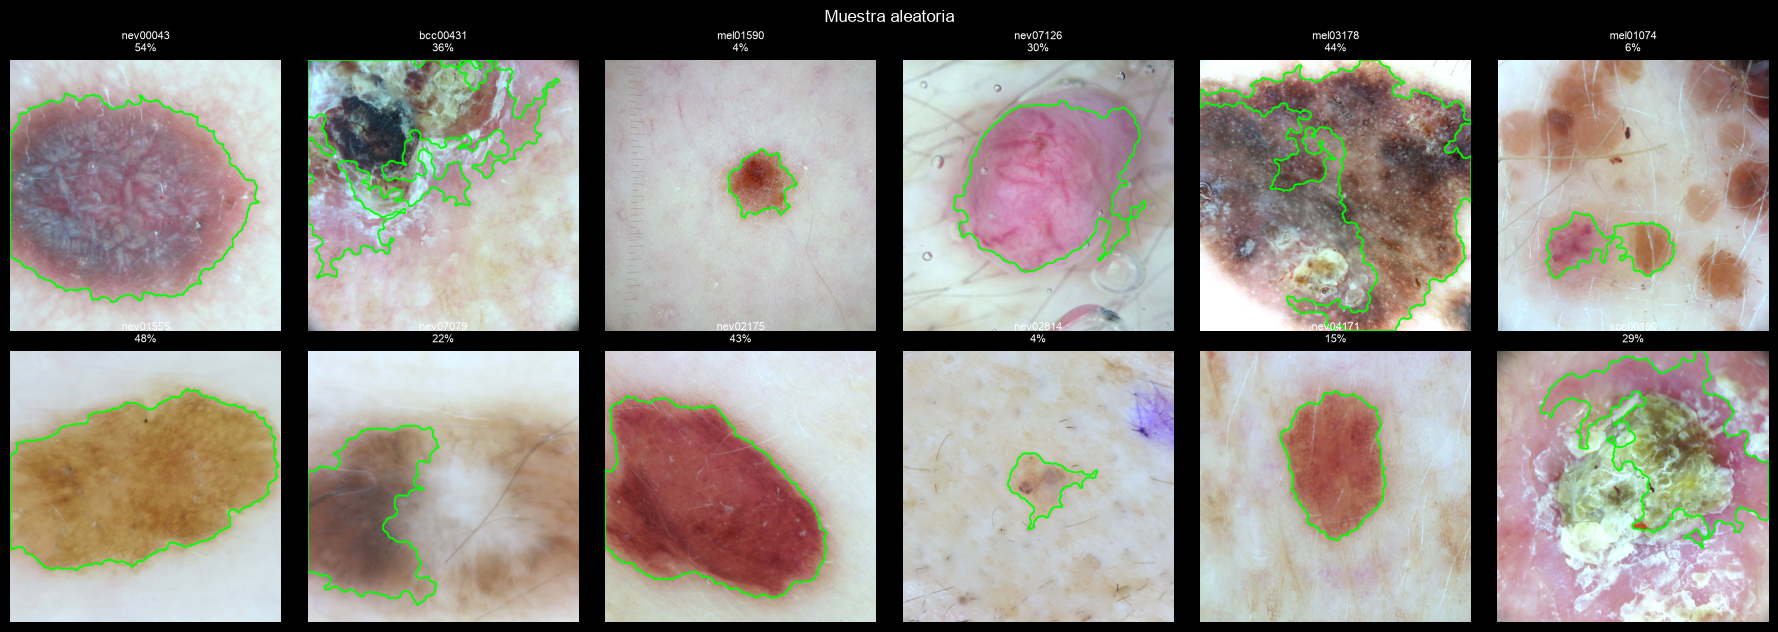

8661 imágenes con seg_ok == False (se muestran hasta 24)


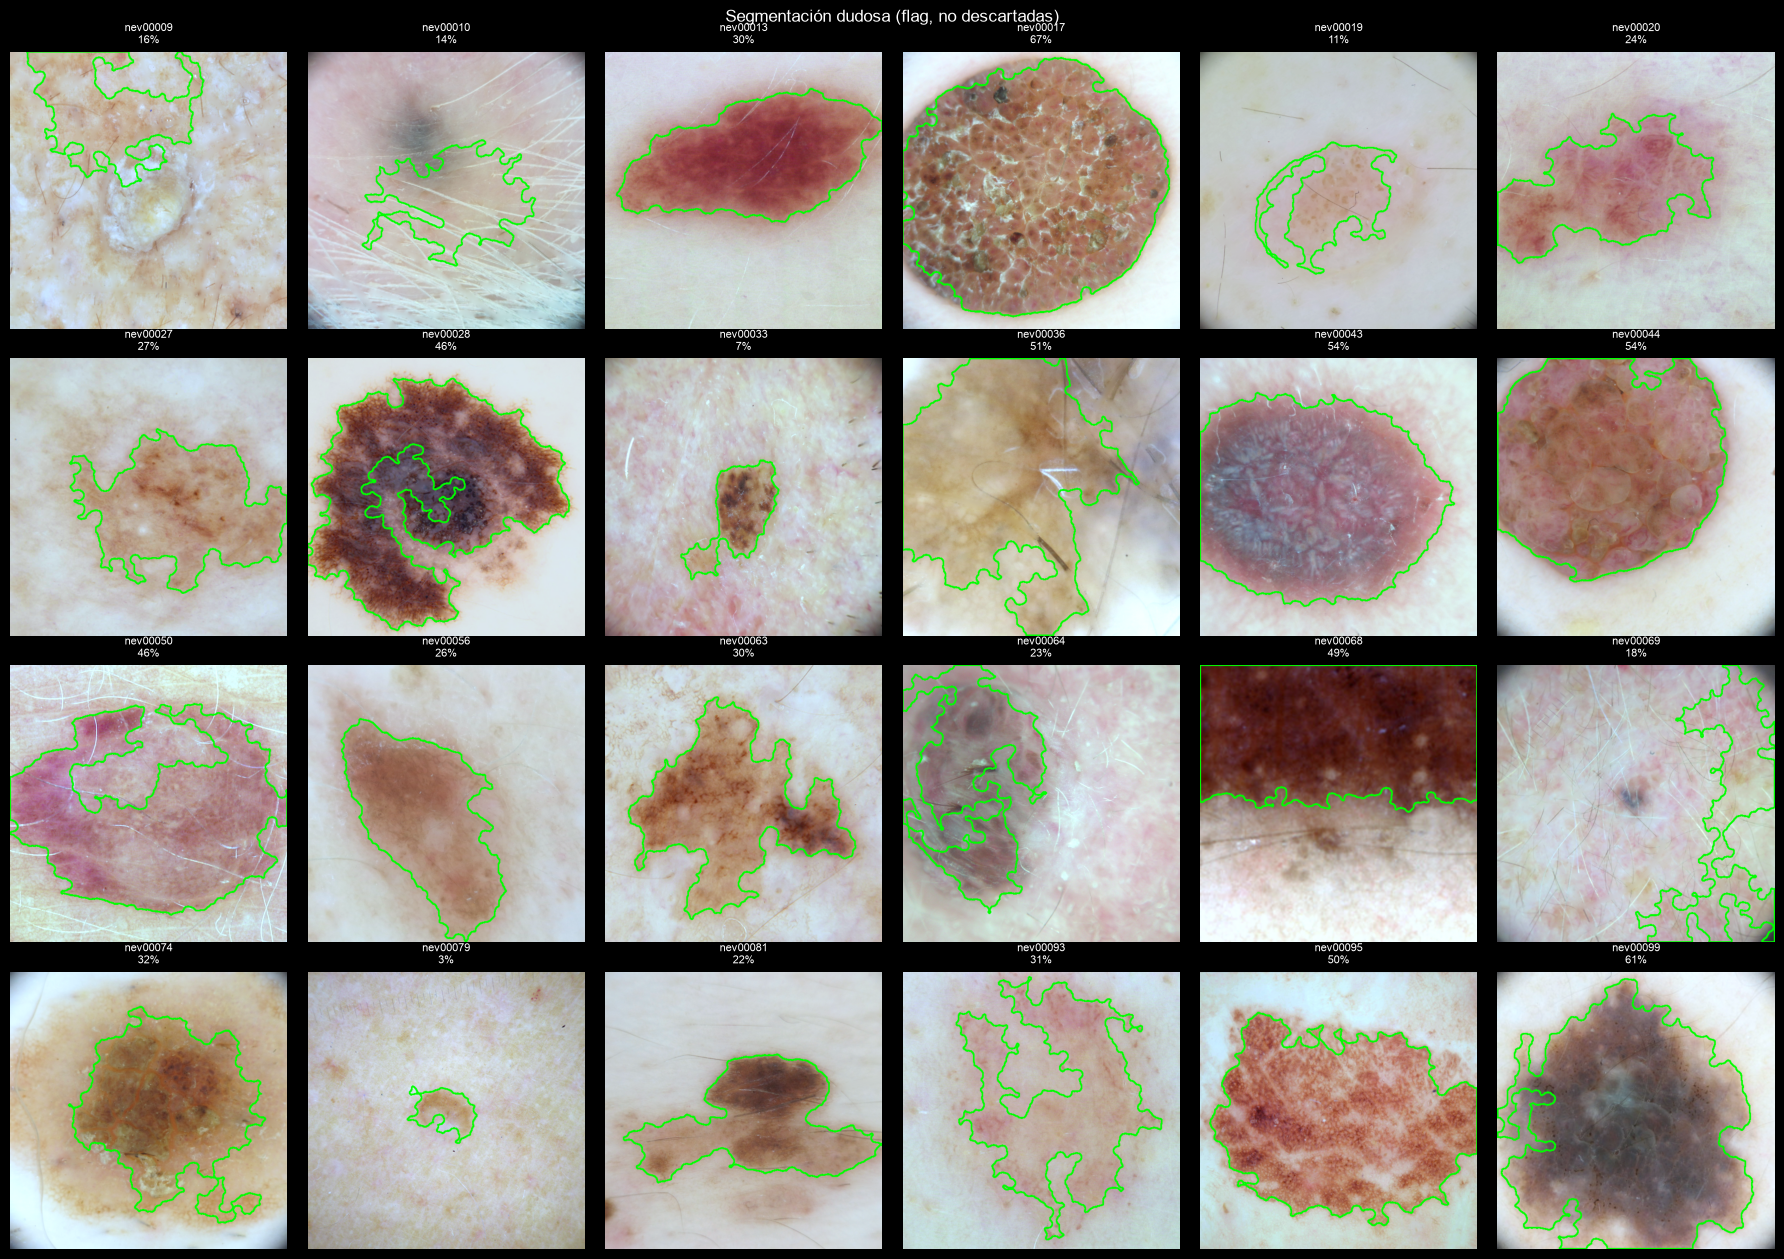

In [6]:
ok_rows = new[new["status"].isin(["ok", "skipped"])]
contact_sheet(ok_rows.sample(min(12, len(ok_rows)), random_state=SEED), title="Random sample")
bad = ok_rows[~ok_rows["seg_ok"].astype(bool)]
print(f"{len(bad)} images with seg_ok == False (showing up to 24)")
if len(bad):
    contact_sheet(bad.head(24), title="Doubtful segmentation (flagged, not discarded)")